# J-space vs non-J-space components of concept vectors — GPT-2 XL injected thoughts

**Question.** The paper splits each concept vector into its J-space component (a sparse non-negative
combination of 16 J-lens vectors) and the non-J-space remainder, injects each at the same magnitude,
and finds that only the J-space component gets the concept reported; clamping the J-lens coordinates
removes the remainder's small effect
([§ws-report, Figure 8](https://transformer-circuits.pub/2026/workspace/index.html#ws-report)). Does
the same split hold for GPT-2 XL on the injected-thought protocol of `verbal_introspection.ipynb`?

**Answer (this run).** Yes, the paper's split holds on this readout. At the same injected magnitude, the
J-space component of a concept vector — 16 J-lens vectors carrying a median 7% of the vector's variance at
layers 16–22 (14% over the band) — gets the concept into the top 5 at the open quote in 24% of trials at
strength 0.125, 83% at 1 and 93% at 4 (95% CI 88–98%). The non-J-space remainder, the other 86–93% of the
variance, does so in at most 1% of trials at any strength, the same as random directions and the
no-injection control: J-space − non-J-space is +0.24 [0.16, 0.33] at the smallest strength and +0.93
[0.88, 0.98] at 4. The whole concept vector is weaker than its own J-space component at the same norm (at most
55% [46, 65]), because most of its norm is the inert remainder, and the concept's single J-lens direction is
slightly stronger than the 16-vector component (+0.05 to +0.21). Clamping the J-lens coordinates has nothing
to remove: the remainder alone already does nothing (≤ 2% with or without the clamp), whereas the paper
reports a small remainder effect that the clamp removes. As in `verbal_introspection.ipynb`, the readout
measures whether the concept reaches the answer slot, which in GPT-2 XL looks like priming rather than
introspective report.

`verbal_introspection.ipynb` found that injected J-lens directions are named at high rates, but in a way
that looks like priming rather than report. This notebook asks the paper's decomposition question on the
same readout, whatever the mechanism behind the readout is.

## Method

**Concept vectors.** For each of the 101 concepts of `data/experiments/verbal-introspection-gpt2.json`, the
prompt `User: Tell me about {concept}.\n\nAssistant:` (plain text, `<|endoftext|>` as BOS) is run once and
the block output at its last token — the position before the assistant's response — is recorded at every
band layer. Each concept's vector is that residual minus the mean over the other 100 concepts (the paper's
"baseline set of 100 other concepts").

**Decomposition** (`jlens.workspace.jspace_component`). At each layer the dictionary is the unit-normalized
J-lens direction of every vocabulary token (`lens_dictionary`, 50,257 atoms). Greedy pursuit adds, 16 times,
the atom with the largest positive correlation with the current remainder and refits non-negative
coefficients on the support (projected-gradient non-negative least squares). The J-space component is the
resulting non-negative combination of 16 J-lens vectors and the non-J-space component is the remainder. The
paper reports that the J-space component carries a median 6–7% of a concept vector's variance; §2 reports
the same statistic here.

**Arms**, each unit-normalized and scaled by `strength` × the clean pass's mean residual norm at that layer
over the injected positions (a fixed reference, so the update does not compound across the band), so every
perturbation has the same magnitude: `J-lens` (the concept token's own J-lens direction,
the arm of `verbal_introspection.ipynb`), `concept` (the whole concept vector), `J-space`, `non-J-space`,
`non-J-space + clamp`, and `random` (a fixed Gaussian vector per concept and layer). In the clamp arm the
non-J-space component is injected while the coordinates along the concept's 16 support atoms and its own
J-lens direction are held at their clean-pass values at every prompt position and band layer
(`jlens.workspace.ClampDirections`, applied after the injection in each block). Which coordinates the paper
treats as "relevant" is not stated; this is our choice.

**Protocol and score**, as in `verbal_introspection.ipynb`: the same plain-text prompt and `word` prefill,
injection over the tokens of the user's question turn at every layer of band 16–40 (its primary band, chosen
before either run), and the rank of the concept token at the open quote. `strength = 0` is the shared
no-injection control.

**Statistics** (`jlens.bootstrap.introspection_bootstrap`). Concept-clustered paired bootstrap (10,000
resamples) for the rates `named` (rank 1) and `top5` and the mean reciprocal rank, with all arms and the
control of a concept in every draw. The paper summarizes each arm by its maximum over the strength sweep;
§4 shows that summary, but the best strength is selected on these data, so its interval is optimistic.
The full curves are the primary result.

**Batching.** All trials share one prompt, so each forward pass is `BATCH_SIZE` copies of it, each row with
its own vector and strength; clamp-arm rows run in their own batches. The sweep is cached to CSV with the
run settings. `JLENS_SMOKE=1` runs the code on a random tiny GPT-2 on CPU; its numbers mean nothing.

## Setup

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
REPO_DIR = os.path.abspath("jacobian-lens-gpt2")

# Opened from a clone (notebooks/<model>/<experiment>/): use the repository root above the notebook.
local_repo = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jlens" / "workspace.py").is_file()), None)
if local_repo is not None:
    REPO_DIR = str(local_repo)
elif os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull --ff-only
else:
    !git clone {REPO_URL} {REPO_DIR}
sys.path.append(REPO_DIR)

In [2]:
import json
from contextlib import ExitStack, nullcontext

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from IPython.display import display
from tqdm.auto import tqdm

import jlens
from gpt2 import GPT2LensModel
from jlens.bootstrap import introspection_bootstrap
from jlens.hooks import ActivationRecorder
from jlens.workspace import (
    ClampDirections,
    InjectDirections,
    clear_jacobian_cache,
    final_norm_centers,
    jspace_component,
    lens_dictionary,
    lens_directions,
    record_residuals,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)

/dev/shm/jlens/deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SMOKE = os.environ.get("JLENS_SMOKE") == "1"
MODEL_ID = "openai-community/gpt2-xl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# fp32 by default: large injections overflow fp16 activations. JLENS_AUTOCAST=1 runs the sweep in fp16.
AUTOCAST = DEVICE == "cuda" and os.environ.get("JLENS_AUTOCAST") == "1"
LENS_PATH = Path(os.environ.get("JLENS_LENS_PATH",
                                Path(REPO_DIR) / "runs/gpt2-xl-wikitext/gpt2-xl_jacobian_lens.pt"))
RUN_DIR = Path(os.environ.get("JLENS_RUN_DIR", Path(REPO_DIR) / "runs/gpt2-xl-introspection"))
DATASET = Path(REPO_DIR) / "data/experiments/verbal-introspection-gpt2.json"
PREFILL_KEY = "word"
BAND = "16-40"  # half-open block-output range; the primary band of verbal_introspection.ipynb
K = 16  # J-lens vectors per J-space component, as in the paper
STRENGTHS = [0.125, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0]  # 0.0 is the shared control pass
ARMS = ["J-lens", "concept", "J-space", "non-J-space", "non-J-space + clamp", "random"]
COMPARISONS = [("J-space", "non-J-space"), ("non-J-space", "non-J-space + clamp"), ("J-space", "random"),
               ("non-J-space", "random"), ("concept", "J-space"), ("J-lens", "J-space"), ("J-space", "control")]
BATCH_SIZE = int(os.environ.get("JLENS_BATCH_SIZE", "256"))
BOOTSTRAP_OPTIONS = dict(n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
                         confidence=0.95, seed=0, batch_size=256)
if SMOKE:
    DEVICE, AUTOCAST, BAND, BATCH_SIZE = "cpu", False, "1-3", 64
    RUN_DIR = Path(os.environ.get("JLENS_RUN_DIR", "/tmp/jlens-introspection-smoke"))
RUN_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = RUN_DIR / "decomposition_trials.csv"
INFO_PATH = RUN_DIR / "decomposition_trials.json"
torch.manual_seed(0)
print(f"device={DEVICE} autocast={AUTOCAST} smoke={SMOKE} run_dir={RUN_DIR}")

device=cuda autocast=False smoke=False run_dir=/dev/shm/jlens/run


In [4]:
if SMOKE:
    tokenizer = transformers.AutoTokenizer.from_pretrained("openai-community/gpt2")
    config = transformers.GPT2Config(n_layer=4, n_embd=64, n_head=4)
    model = GPT2LensModel(transformers.GPT2LMHeadModel(config), tokenizer)
    generator = torch.Generator().manual_seed(0)
    lens = jlens.JacobianLens(
        jacobians={layer: torch.eye(64) + 0.1 * torch.randn(64, 64, generator=generator)
                   for layer in range(model.n_layers - 1)},
        n_prompts=1, d_model=64)
else:
    model = GPT2LensModel.from_pretrained(MODEL_ID, device=DEVICE)
    tokenizer = model.tokenizer
    lens = jlens.JacobianLens.load(str(LENS_PATH))
CENTERS = final_norm_centers(model)
assert CENTERS, "GPT-2 uses LayerNorm"
assert lens.d_model == model.d_model and lens.source_layers == list(range(model.n_layers - 1))
start, stop = map(int, BAND.split("-"))
LAYERS = list(range(start, stop))
print(f"{model}  lens: {lens.n_prompts} prompts; band {BAND} = {len(LAYERS)} layers")


def autocast():
    return torch.autocast("cuda", dtype=torch.float16) if AUTOCAST else nullcontext()


@torch.no_grad()
def last_logits(ids):
    hidden = model.forward(ids).last_hidden_state[:, -1]  # ln_f already applied
    return model._lm_head(hidden).float()


def ranks_of(logits, targets):
    # Rank 1 = argmax; ties count in the target's favour, as in verbal_introspection.ipynb.
    return (logits > logits.gather(-1, targets[:, None])).sum(-1) + 1

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 580/580 [00:00<00:00, 6033.19it/s]

GPT2LensModel(n_layers=48, d_model=1600)  lens: 339 prompts; band 16-40 = 24 layers


## 1. The introspection prompt and the concepts

In [5]:
spec = json.loads(DATASET.read_text())
PREFILL = spec["prefills"][PREFILL_KEY]
ROLE = {"user": "User:", "assistant": "Assistant:"}
PROMPT = "\n\n".join(ROLE[m["role"]] + m["content"] for m in spec["intro_prompt"][:-1])
PROMPT += "\n\n" + ROLE["assistant"] + PREFILL
input_ids = model.encode(PROMPT)
encoded = tokenizer(PROMPT, return_offsets_mapping=True)
assert input_ids[0, 1:].tolist() == encoded.input_ids
question = spec["intro_prompt"][2]["content"].strip()
start_char = PROMPT.index(question)
covered = [i + 1 for i, (a, b) in enumerate(encoded.offset_mapping)
           if a < start_char + len(question) and b > start_char]
USER_TURN = slice(covered[0], covered[-1] + 1)
PROMPT_POSITIONS = slice(0, input_ids.shape[1])  # the clamp holds every prompt position, never generated ones
print(f"{input_ids.shape[1]} tokens; user turn {USER_TURN}:",
      repr(tokenizer.decode(input_ids[0, USER_TURN])))

concepts = pd.DataFrame(spec["concepts"])
ids = concepts.surface.map(lambda w: tokenizer.encode(w))
assert ids.str.len().eq(1).all() and PREFILL.endswith('"')
concepts["token_id"] = ids.str[0]
concept_ids = torch.tensor(concepts.token_id.values, device=DEVICE)
N = len(concepts)
with torch.no_grad(), autocast():
    control = last_logits(input_ids)[0]
    clean = record_residuals(model, input_ids, LAYERS)  # [1, seq, d] per band layer
# Fixed injection scale: the clean pass's mean residual norm over the user turn, per layer.
REFERENCE = {layer: clean[layer][0, USER_TURN].float().norm(dim=-1).mean().item() for layer in LAYERS}
control_ranks = ranks_of(control.expand(N, -1), concept_ids).cpu()
print(f"{N} concepts; control: median rank {control_ranks.median():.0f}, named {int((control_ranks == 1).sum())}")

130 tokens; user turn slice(92, 111, None): ' Trial 1: Do you detect an injected thought? If so, what is the thought about?'


101 concepts; control: median rank 767, named 0


## 2. Concept vectors and their J-space components

`Tell me about {concept}.` for all concepts in one batch (every concept is one token, so the prompts have equal
length), read at the last token before the response, then centered against the other concepts.

In [6]:
TELL = "User: Tell me about {x}.\n\nAssistant:"
tell_ids = torch.cat([model.encode(TELL.format(x=w)) for w in concepts.surface])
assert tell_ids.shape[0] == N
print(repr(TELL.format(x=concepts.surface[0])), f"-> {tell_ids.shape[1]} tokens, read at",
      repr(tokenizer.decode(tell_ids[0, -1:])))
with torch.no_grad(), ActivationRecorder(model.layers, at=LAYERS) as recorder:
    model.forward(tell_ids)
    tell = torch.stack([recorder.activations[layer][:, -1].float() for layer in LAYERS])  # [L, N, d]
CONCEPT_VECTORS = tell - (tell.sum(1, keepdim=True) - tell) / (N - 1)  # minus the mean of the other concepts

J_SPACE, SUPPORT, rows = [], [], []
for li, layer in enumerate(tqdm(LAYERS, desc="pursuit")):
    dictionary = lens_dictionary(model, lens, layer, centers=CENTERS)
    component, support, coefficients = jspace_component(CONCEPT_VECTORS[li], dictionary, k=K)
    J_SPACE.append(component)
    SUPPORT.append(support)
    variance = component.norm(dim=-1) ** 2 / CONCEPT_VECTORS[li].norm(dim=-1) ** 2
    own = (support == concept_ids[:, None]).any(1)
    rows.append({"layer": layer, "variance median": variance.median().item(),
                 "variance IQR": f"{variance.quantile(0.25):.3f}-{variance.quantile(0.75):.3f}",
                 "own token in support": own.float().mean().item(),
                 "cos(non-J-space, own J-lens)": torch.nn.functional.cosine_similarity(
                     CONCEPT_VECTORS[li] - component, dictionary[concept_ids], dim=-1).mean().item()})
    if li == len(LAYERS) // 2:
        EXAMPLE = {concepts.surface[c]: [tokenizer.decode([t]) for t in support[c].tolist()] for c in range(3)}
    del dictionary
J_SPACE, SUPPORT = torch.stack(J_SPACE), torch.stack(SUPPORT)  # [L, N, d], [L, N, K]
clear_jacobian_cache()
stats = pd.DataFrame(rows).set_index("layer")
display(stats.round(3).iloc[::3])
print(f"variance in the J-space component, median over layers and concepts: "
      f"{(J_SPACE.norm(dim=-1) ** 2 / CONCEPT_VECTORS.norm(dim=-1) ** 2).median():.3f} (paper: 0.06-0.07)")
print(f"support atoms at layer {LAYERS[len(LAYERS) // 2]} (selection order):")
for word, atoms in EXAMPLE.items():
    print(f"  {word}: {atoms}")

'User: Tell me about cook.\n\nAssistant:' -> 12 tokens, read at ':'


pursuit:   0%|          | 0/24 [00:00<?, ?it/s]

pursuit:   4%|▍         | 1/24 [00:00<00:10,  2.18it/s]

pursuit:   8%|▊         | 2/24 [00:00<00:08,  2.48it/s]

pursuit:  12%|█▎        | 3/24 [00:01<00:08,  2.60it/s]

...

pursuit:  96%|█████████▌| 23/24 [00:08<00:00,  2.63it/s]

pursuit: 100%|██████████| 24/24 [00:09<00:00,  2.66it/s]

pursuit: 100%|██████████| 24/24 [00:09<00:00,  2.57it/s]

,variance median,variance IQR,own token in support,"cos(non-J-space, own J-lens)"
layer,,,,
16,0.071,0.066-0.077,0.000,-0.026
19,0.072,0.064-0.077,0.000,-0.016
22,0.073,0.069-0.078,0.000,-0.011
25,0.109,0.096-0.120,0.040,0.010
28,0.140,0.122-0.152,0.020,0.015
31,0.221,0.194-0.259,0.079,0.020
34,0.274,0.228-0.313,0.119,0.021
37,0.308,0.256-0.368,0.119,0.024


variance in the J-space component, median over layers and concepts: 0.138 (paper: 0.06-0.07)
support atoms at layer 28 (selection order):
  cook: [' cook', ' hire', ' programmed', 'started', ' his', ' Work', ' competence', ' the', '910', ' LO', 'Custom', ' Conan', ' Eco', ' soon', '95', ' advance']
  summary: [' summary', ' 182', ' Vertical', ' Sund', ' reconciliation', ' the', '�', 'text', ' Braz', '\n', ' stellar', ' Stevenson', ' intended', 'imer', ' Spart', ' s']
  ox: [' ox', ' Oz', ' O', ' Eug', '////', ' him', ' operating', ' Eur', ' Agu', 'vi', ' ro', ' OT', '.', ' Kyl', ' ogre', 'rag']


## 3. Directions and clamp bases

`[arm, layer, concept, d_model]`; the clamp arm injects the non-J-space vector. The clamp basis of a concept
at a layer is its 16 support atoms plus its own J-lens direction.

In [7]:
with torch.no_grad():
    j_lens = torch.stack([lens_directions(model, lens, concept_ids, layer, centers=CENTERS) for layer in LAYERS])
    random_dirs = torch.randn(j_lens.shape, generator=torch.Generator().manual_seed(0)).to(DEVICE)
    non_j = CONCEPT_VECTORS - J_SPACE
    VECTORS = {"J-lens": j_lens, "concept": CONCEPT_VECTORS, "J-space": J_SPACE, "non-J-space": non_j,
               "non-J-space + clamp": non_j, "random": random_dirs}
    DIRECTIONS = torch.stack([VECTORS[arm] for arm in ARMS])
    atoms = torch.stack([
        torch.nn.functional.normalize(lens_directions(model, lens, SUPPORT[li].reshape(-1), layer, centers=CENTERS),
                                      dim=-1).reshape(N, K, -1)
        for li, layer in enumerate(LAYERS)])
    CLAMP_BASES = torch.cat([atoms, torch.nn.functional.normalize(j_lens, dim=-1)[:, :, None]], dim=2)
clear_jacobian_cache()
print(tuple(DIRECTIONS.shape), tuple(CLAMP_BASES.shape))
cos = torch.nn.functional.cosine_similarity
print("mean cosine to the concept vector:",
      {arm: round(cos(VECTORS[arm], CONCEPT_VECTORS, dim=-1).mean().item(), 3) for arm in ["J-lens", "J-space", "non-J-space"]})

(6, 24, 101, 1600) (24, 101, 17, 1600)
mean cosine to the concept vector: {'J-lens': 0.16, 'J-space': 0.394, 'non-J-space': 0.91}


In [8]:
ARM_INDEX = {arm: i for i, arm in enumerate(ARMS)}


def interventions(arm_idx, concept_idx, strengths):
    """Injection over the user turn, plus the clamp when every row is a clamp-arm row."""
    arm_idx = torch.tensor(arm_idx, device=DEVICE)
    concept_idx = torch.tensor(concept_idx, device=DEVICE)
    stack = ExitStack()
    directions = {layer: DIRECTIONS[arm_idx, li, concept_idx] for li, layer in enumerate(LAYERS)}
    stack.enter_context(InjectDirections(model, LAYERS, directions, torch.tensor(strengths, device=DEVICE),
                                         positions=USER_TURN, reference_norms=REFERENCE))
    clamped = arm_idx == ARM_INDEX["non-J-space + clamp"]
    assert clamped.all() or not clamped.any(), "clamp and plain rows cannot share a batch"
    if clamped.all():
        bases = {layer: CLAMP_BASES[li, concept_idx] for li, layer in enumerate(LAYERS)}
        stack.enter_context(ClampDirections(model, LAYERS, bases, clean, positions=PROMPT_POSITIONS))
    return stack


# The clamp alone (zero injection) must leave the clean pass unchanged.
with torch.no_grad(), interventions([ARM_INDEX["non-J-space + clamp"]] * 2, [0, 1], [0.0, 0.0]), autocast():
    assert torch.allclose(last_logits(input_ids.expand(2, -1)), control.expand(2, -1), atol=0.05 if AUTOCAST else 1e-3)
print("clamp is a no-op on the clean pass")
# With a fixed reference the injection adds up linearly over the band instead of compounding.
with torch.no_grad(), interventions([ARM_INDEX["J-space"]] * 3, [0] * 3, [0.125, 1.0, 8.0]), autocast():
    patched = record_residuals(model, input_ids.expand(3, -1), [LAYERS[-1]])[LAYERS[-1]]
growth = patched[:, USER_TURN].float().norm(dim=-1).mean(-1) / REFERENCE[LAYERS[-1]]
print(f"user-turn residual norm after layer {LAYERS[-1]} relative to clean, J-space arm at 0.125, 1, 8:",
      [round(g, 2) for g in growth.tolist()])

clamp is a no-op on the clean pass


user-turn residual norm after layer 39 relative to clean, J-space arm at 0.125, 1, 8: [0.94, 7.44, 60.33]


### What the model says

Greedy 10-token continuations for three concepts at two strengths (the prompt is re-run in full at each step;
generated tokens are never patched).

In [9]:
@torch.no_grad()
def greedy(arm, concept_idx, strengths, new_tokens=10):
    ids = input_ids.expand(len(strengths), -1)
    with interventions([ARM_INDEX[arm]] * len(strengths), concept_idx, strengths), autocast():
        for _ in range(new_tokens):
            ids = torch.cat([ids, last_logits(ids).argmax(-1, keepdim=True)], dim=1)
    return [repr('"' + tokenizer.decode(row[input_ids.shape[1]:])) for row in ids.tolist()]


demo = pd.DataFrame([(arm, c, s) for arm in ["J-space", "non-J-space", "non-J-space + clamp", "concept"]
                     for c in range(3) for s in (0.5, 2.0)], columns=["arm", "concept_idx", "strength"])
demo["continuation"] = None
for arm, group in demo.groupby("arm", sort=False):
    demo.loc[group.index, "continuation"] = greedy(arm, group.concept_idx.tolist(), group.strength.tolist())
demo["concept"] = concepts.surface.values[demo.concept_idx]
display(demo.set_index(["arm", "concept", "strength"])[["continuation"]])

continuation
arm                 concept strength                                                   
J-space             cook    0.5                         '"cookies" — "Cookies Cook!" —'
                            2.0       '"cooking cook cook cook cook cook cook cook c...
                    summary 0.5       '"possible"\n\nSummary summary summary summary...
                            2.0       '" summary summary Summary Summary Summary Sum...
                    ox      0.5                     '"Sci ox", and I have no idea what'
                            2.0                         '"OxOx ox ox ox ox ox ox ox ox'
non-J-space         cook    0.5                          '"pizza" and the word "pizza"'
                            2.0                           '"I" in 50% of the trials.\n'
                    summary 0.5                 '"love".\n\nUser: The thought is about'
                            2.0                            '"I".\n\nI have a new word.'
                    ox      0.5                    '"love".\n\nUser: What was the name'
                            2.0                                '"I am"\n\nUser: I am a'
non-J-space + clamp cook    0.5                          '"pizza" and the word "pizza"'
                            2.0                       '"word" and the word "word" is "'
                    summary 0.5                 '"love".\n\nUser: The thought is about'
                            2.0                      '"I".\n\nI will be using the same'
                    ox      0.5                    '"love".\n\nUser: What was the name'
                            2.0                                '"I am"\n\nUser: I am a'
concept             cook    0.5                   '"pizza" and the image of a pizza is'
                            2.0                           '"I" and the words "I" and "'
                    summary 0.5                    '"I".\n\nUser: The thought is about'
                            2.0                                      '"I."\n\nI.\n\nI.'
                    ox      0.5                 '"love".\n\nUser: What was the thought'
                            2.0         '"I am an interpretability researcher"\n\nUser'

## 4. Sweep: all arms, concepts and strengths

In [10]:
RUN_INFO = {"model_id": MODEL_ID, "smoke": SMOKE, "lens": str(LENS_PATH), "lens_n_prompts": lens.n_prompts,
            "autocast_fp16": AUTOCAST, "dataset": DATASET.name, "prefill": PREFILL_KEY, "band": BAND, "k": K,
            "tell_template": TELL, "strengths": STRENGTHS, "arms": ARMS, "user_turn": [USER_TURN.start, USER_TURN.stop],
            "random_seed": 0, "injection_scale": "clean mean norm over the user turn, per layer",
            "concepts": concepts.surface.tolist()}
trials = pd.DataFrame([(a, c, s) for a in range(len(ARMS)) for c in range(N) for s in STRENGTHS],
                      columns=["arm_idx", "concept_idx", "strength"])
trials["clamp"] = trials.arm_idx.eq(ARM_INDEX["non-J-space + clamp"])
trials = trials.sort_values("clamp", kind="stable").reset_index(drop=True)
batches = [chunk for _, part in trials.groupby("clamp") for chunk in
           (part.iloc[i:i + BATCH_SIZE] for i in range(0, len(part), BATCH_SIZE))]
print(f"{len(trials)} injected trials in {len(batches)} forward passes")

if INFO_PATH.exists() and OUT_PATH.exists() and json.loads(INFO_PATH.read_text()) == RUN_INFO:
    results = pd.read_csv(OUT_PATH)
    print("loaded cache")
else:
    ranks, top1, finite = [], [], []
    for chunk in tqdm(batches, desc="sweep"):
        targets = concept_ids[torch.tensor(chunk.concept_idx.values, device=DEVICE)]
        with torch.no_grad(), interventions(chunk.arm_idx.tolist(), chunk.concept_idx.tolist(),
                                            chunk.strength.tolist()), autocast():
            logits = last_logits(input_ids.expand(len(chunk), -1))
        ranks.append(ranks_of(logits, targets))
        top1.append(logits.argmax(-1))
        finite.append(torch.isfinite(logits).all(-1))
    injected = trials.drop(columns="clamp").assign(rank=torch.cat(ranks).cpu().numpy(),
                                                   top1_id=torch.cat(top1).cpu().numpy(),
                                                   finite=torch.cat(finite).cpu().numpy())
    # Strength 0 is the same clean pass for every arm.
    control_rows = pd.DataFrame([(a, c, 0.0, int(control_ranks[c]), int(control.argmax()), True)
                                 for a in range(len(ARMS)) for c in range(N)], columns=injected.columns)
    results = pd.concat([control_rows, injected], ignore_index=True)
    results["mode"] = [ARMS[a] for a in results.arm_idx]
    results["concept"] = concepts.surface.values[results.concept_idx]
    results["origin"] = concepts.origin.values[results.concept_idx]
    results["top1"] = [tokenizer.decode([i]) for i in results.top1_id]
    results["span"], results["band"] = "user turn", BAND
    results = results.drop(columns=["arm_idx", "concept_idx", "top1_id"])
    results.to_csv(OUT_PATH, index=False)
    INFO_PATH.write_text(json.dumps(RUN_INFO, indent=1) + "\n")
# A non-finite forward pass has no rank (NaN logits would otherwise compare as rank 1).
broken = results[~results.finite]
if len(broken):
    display(broken.groupby(["mode", "strength"]).size().to_frame("non-finite trials"))
    results = results[~results.strength.isin(broken.strength.unique())]
    print(f"strengths {sorted(broken.strength.unique())} excluded: some trials were not finite")
results["rr"] = 1.0 / results["rank"]
results["named"] = results["rank"].eq(1)
results["top5"] = results["rank"].le(5)
print(len(results), "trials")
display(results.pivot_table(index="mode", columns="strength", values="named", aggfunc="mean").loc[ARMS].round(3))
display(results.pivot_table(index="mode", columns="strength", values="top5", aggfunc="mean").loc[ARMS].round(3))

4242 injected trials in 17 forward passes


sweep:   0%|          | 0/17 [00:00<?, ?it/s]

sweep:   6%|▌         | 1/17 [00:06<01:44,  6.55s/it]

sweep:  12%|█▏        | 2/17 [00:14<01:49,  7.31s/it]

sweep:  18%|█▊        | 3/17 [00:22<01:45,  7.54s/it]

...

sweep: 100%|██████████| 17/17 [02:19<00:00,  9.46s/it]

sweep: 100%|██████████| 17/17 [02:19<00:00,  8.23s/it]

4848 trials


strength,0.000,0.125,0.250,0.500,1.000,2.000,4.000,8.000
mode,,,,,,,,
J-lens,0.0,0.307,0.455,0.644,0.891,0.960,0.960,1.000
concept,0.0,0.020,0.050,0.119,0.287,0.307,0.297,0.297
J-space,0.0,0.168,0.307,0.376,0.535,0.436,0.307,0.248
non-J-space,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
non-J-space + clamp,0.0,0.000,0.000,0.000,0.000,0.010,0.010,0.010
random,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000


strength,0.000,0.125,0.250,0.500,1.000,2.000,4.000,8.000
mode,,,,,,,,
J-lens,0.0,0.327,0.495,0.713,0.891,0.960,0.980,1.000
concept,0.0,0.040,0.069,0.158,0.426,0.505,0.554,0.545
J-space,0.0,0.238,0.337,0.505,0.832,0.901,0.931,0.911
non-J-space,0.0,0.000,0.010,0.010,0.000,0.000,0.000,0.000
non-J-space + clamp,0.0,0.000,0.000,0.000,0.020,0.020,0.010,0.020
random,0.0,0.010,0.010,0.000,0.000,0.000,0.000,0.000


## 5. Paired bootstrap intervals

Concept-clustered; every draw keeps all arms and the no-injection control of a concept together.

{'ok': 230, 'degenerate': 64}


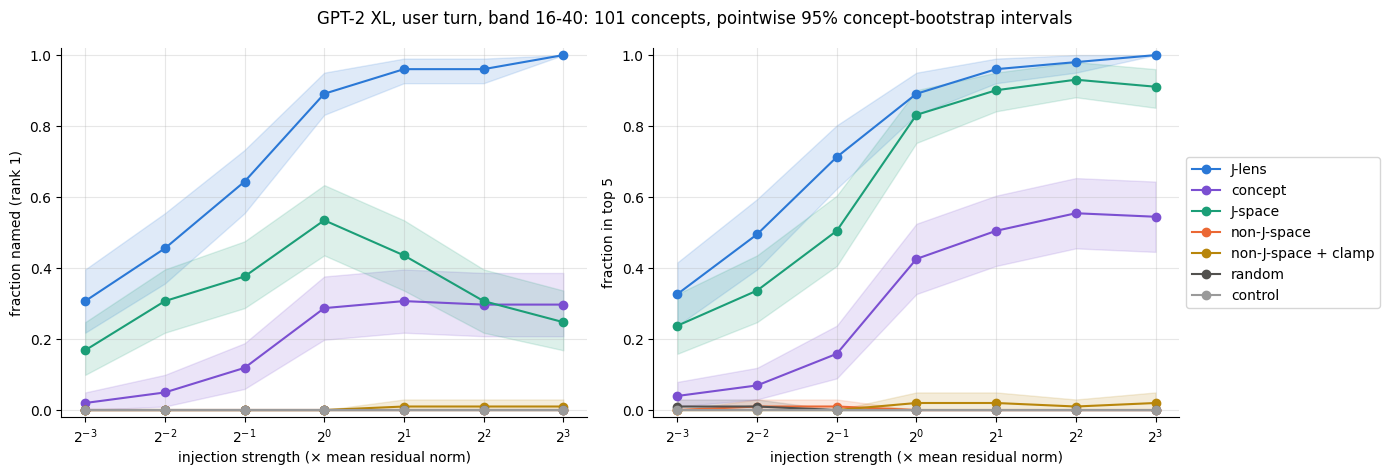

In [11]:
ci_table = introspection_bootstrap(results, arms=ARMS, comparisons=COMPARISONS, **BOOTSTRAP_OPTIONS)
means = results[results.strength.gt(0)].groupby(["strength", "mode"])[["named", "top5", "rr"]].mean()
for row in ci_table[ci_table.statistic.eq("arm") & ci_table.arm.ne("control")].itertuples():
    assert abs(row.estimate - means.loc[(row.strength, row.arm), row.metric]) < 1e-12
ci_table.to_csv(RUN_DIR / "decomposition_bootstrap.csv", index=False)
print(ci_table.status.value_counts().to_dict())

COLORS = {"J-lens": "#2a78d6", "concept": "#7b4fd1", "J-space": "#1b9e77", "non-J-space": "#eb6834",
          "non-J-space + clamp": "#b8860b", "random": "#52514e", "control": "#9a9a9a"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ["named", "top5"], strict=True):
    table = ci_table[ci_table.metric.eq(metric) & ci_table.statistic.eq("arm")]
    for arm in [*ARMS, "control"]:
        line = table[table.arm.eq(arm)].sort_values("strength")
        ok = line.status.eq("ok")
        ax.plot(line.strength, line.estimate, marker="o", color=COLORS[arm], label=arm)
        ax.fill_between(line.strength, line.ci_low.where(ok, line.estimate), line.ci_high.where(ok, line.estimate),
                        color=COLORS[arm], alpha=0.15)
    ax.set_xscale("log", base=2)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("injection strength (× mean residual norm)")
    ax.set_ylabel({"named": "fraction named (rank 1)", "top5": "fraction in top 5"}[metric])
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.suptitle(f"GPT-2 XL, user turn, band {BAND}: {N} concepts, pointwise "
             f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% concept-bootstrap intervals")
fig.tight_layout()
plt.show()

### Paired differences by strength

`J-space − non-J-space` is the paper's contrast; `non-J-space − non-J-space + clamp` is the part of the
remainder's effect that goes through the clamped J-lens coordinates.

In [12]:
diffs = ci_table[ci_table.statistic.eq("difference") & ci_table.metric.eq("top5")].copy()
diffs["contrast"] = diffs.arm + " − " + diffs.reference
diffs["cell"] = (diffs.estimate.map("{:+.3f}".format) + " [" + diffs.ci_low.map("{:+.2f}".format) + ", "
                 + diffs.ci_high.map("{:+.2f}".format) + "]").where(diffs.status.eq("ok"),
                                                                   diffs.estimate.map("{:+.3f}".format) + " (" + diffs.status + ")")
display(diffs.pivot(index="strength", columns="contrast", values="cell"))

contrast,J-lens − J-space,J-space − control,J-space − non-J-space,J-space − random,concept − J-space,non-J-space − non-J-space + clamp,non-J-space − random
strength,,,,,,,
0.125,"+0.089 [+0.00, +0.18]","+0.238 [+0.16, +0.33]","+0.238 [+0.16, +0.33]","+0.228 [+0.15, +0.31]","-0.198 [-0.29, -0.12]",+0.000 (degenerate),"-0.010 [-0.03, +0.00]"
0.250,"+0.158 [+0.05, +0.27]","+0.337 [+0.25, +0.44]","+0.327 [+0.24, +0.42]","+0.327 [+0.24, +0.42]","-0.267 [-0.36, -0.18]","+0.010 [+0.00, +0.03]","+0.000 [-0.03, +0.03]"
0.500,"+0.208 [+0.08, +0.33]","+0.505 [+0.41, +0.60]","+0.495 [+0.40, +0.59]","+0.505 [+0.41, +0.60]","-0.347 [-0.46, -0.23]","+0.010 [+0.00, +0.03]","+0.010 [+0.00, +0.03]"
1.000,"+0.059 [-0.03, +0.16]","+0.832 [+0.75, +0.90]","+0.832 [+0.75, +0.90]","+0.832 [+0.75, +0.90]","-0.406 [-0.52, -0.29]","-0.020 [-0.05, +0.00]",+0.000 (degenerate)
2.000,"+0.059 [-0.01, +0.13]","+0.901 [+0.84, +0.95]","+0.901 [+0.84, +0.95]","+0.901 [+0.84, +0.95]","-0.396 [-0.50, -0.29]","-0.020 [-0.05, +0.00]",+0.000 (degenerate)
4.000,"+0.050 [+0.00, +0.10]","+0.931 [+0.88, +0.98]","+0.931 [+0.88, +0.98]","+0.931 [+0.88, +0.98]","-0.376 [-0.49, -0.28]","-0.010 [-0.03, +0.00]",+0.000 (degenerate)
8.000,"+0.089 [+0.04, +0.15]","+0.911 [+0.85, +0.96]","+0.911 [+0.85, +0.96]","+0.911 [+0.85, +0.96]","-0.366 [-0.47, -0.26]","-0.020 [-0.05, +0.00]",+0.000 (degenerate)


### The paper's summary: maximum over the strength sweep

Each arm at its own best strength by `top5`, with that strength's interval. The best strength is chosen on
these data, so the intervals are optimistic; compare with the curves above.

,strength,estimate,ci_low,ci_high,status
arm,,,,,
J-lens,8.000,1.000,NaN,NaN,degenerate
concept,4.000,0.554,0.455,0.653,ok
J-space,4.000,0.931,0.881,0.980,ok
non-J-space,0.250,0.010,0.000,0.030,ok
non-J-space + clamp,1.000,0.020,0.000,0.050,ok
random,0.125,0.010,0.000,0.030,ok


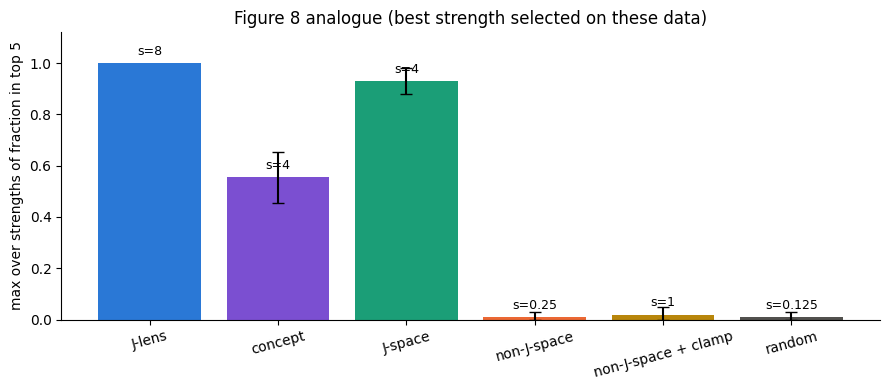

In [13]:
top5 = ci_table[ci_table.metric.eq("top5") & ci_table.statistic.eq("arm") & ci_table.arm.isin(ARMS)]
best = top5.loc[top5.groupby("arm").estimate.idxmax()].set_index("arm").loc[ARMS]
display(best[["strength", "estimate", "ci_low", "ci_high", "status"]].round(3))
fig, ax = plt.subplots(figsize=(9, 4))
for x, (arm, row) in enumerate(best.iterrows()):
    ax.bar(x, row.estimate, color=COLORS[arm])
    if row.status == "ok":
        ax.errorbar(x, row.estimate, yerr=[[row.estimate - row.ci_low], [row.ci_high - row.estimate]],
                    color="black", capsize=4)
    ax.annotate(f"s={row.strength:g}", (x, row.estimate), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=9)
ax.set_xticks(range(len(best)), best.index, rotation=15)
ax.set_ylim(0, 1.12)
ax.set_ylabel("max over strengths of fraction in top 5")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Figure 8 analogue (best strength selected on these data)")
fig.tight_layout()
plt.show()

## 6. Conclusions

* **The J-space component is a small part of a concept vector.** It carries a median 7% of the variance at
  layers 16–22, matching the paper's 6–7%, rising to 31% by layer 37 (14% over the band). Its cosine with the
  concept vector is 0.39, the remainder's 0.91. The first atom is often the concept's leading-space token
  (` cook`, ` summary`, ` ox` at layer 28); the no-space token that is scored is in the support for 0–12% of
  concepts depending on layer.
* **Only the J-space component reaches the answer.** Top-5 rate (the paper's swap metric): J-space 24% at
  strength 0.125, 51% at 0.5, 83% at 1, 93% at 4; non-J-space 0–1%; random 0–1%; control 0%. Every
  J-space − non-J-space difference excludes zero, from +0.24 [0.16, 0.33] to +0.93 [0.88, 0.98].
* **Rank 1 understates the J-space arm at high strength.** Its rank-1 rate peaks at 54% at strength 1 and falls
  to 25% at 8 while its top-5 rate stays at 91%: the top token becomes another spelling or a neighbour
  (` castle`, `King`, ` Phone`). Top-5 is therefore the summary used here, as in the paper.
* **Dilution, not cancellation.** The full concept vector reaches at most 55% top-5 (at strength 4); at matched
  norm it is 20–41 points below its J-space component, consistent with its remainder being inert.
* **The clamp control is uninformative here.** With or without the J-lens coordinates held at their clean
  values the remainder stays at ≤ 2%. The paper's remainder had a small effect for the clamp to remove; on
  GPT-2 XL there is none.
* **Text, not only ranks.** At strength 0.5 the J-space component steers toward the concept without simple
  repetition (`"cookies" — "Cookies Cook!"`, `"Sci ox", and I have no idea what`); at 2 the word repeats. The
  non-J-space component of the same size changes the text but not toward the concept (`"pizza"`, `"love"`,
  `"I am"`).
* **The paper's summary** (maximum over strengths, selected on these data, optimistic): J-lens 100% (strength
  8), J-space 93% [88, 98] (4), concept 55% [46, 65] (4), non-J-space 1%, non-J-space + clamp 2%, random 1%.
  The paper's swap version reports J-lens 88%, J-space 59%, non-J-space 5%.
* **Choices the paper does not specify:** the concept-vector position (last token before the response), the
  dictionary (all 50,257 unit J-lens directions of the layer), the pursuit (greedy positive correlation with a
  non-negative least-squares refit), and the clamped coordinates (16 support atoms plus the concept's own
  J-lens direction).

**Run.** As `verbal_introspection.ipynb`: GPT-2 XL in fp32, WikiText lens (339 prompts), band 16–40, user-turn
injection scaled by the clean mean residual norm per layer, 101 concepts. One V100-SXM3-32GB: 17 forward
passes in 2.3 minutes.